<a href="https://colab.research.google.com/github/lexie009/CBB6340/blob/main/CBB6340_Calculus_E1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

In [2]:
# Use a rounded population for a simplified New Haven scenario.
N = 135_000

# Assume one infectious individual and no pre-existing immunity.
I0 = 1
R0 = 0
S0 = N - I0 - R0

# Replace these example values if the assignment specifies other rates.
beta = 0.3
gamma = 0.1

# Define operational clearance as fewer than one infectious individual.
CLEARANCE_THRESHOLD = 1.0

print(f"Total population: {N:,}")
print(f"Initial susceptible population: {S0:,}")
print(f"Initial infectious population: {I0}")
print(f"Initial removed population: {R0}")
print(f"Transmission rate: {beta} per day")
print(f"Removal rate: {gamma} per day")
print(f"Mean infectious duration: {1 / gamma:.1f} days")

Total population: 135,000
Initial susceptible population: 134,999
Initial infectious population: 1
Initial removed population: 0
Transmission rate: 0.3 per day
Removal rate: 0.1 per day
Mean infectious duration: 10.0 days


In [3]:
def simulate_sir(S0, I0, R0, beta, gamma, dt, t_max):
    """Simulate the SIR model using the explicit Euler method."""

    initial = np.array([S0, I0, R0], dtype=float)

    if not np.all(np.isfinite(initial)) or np.any(initial < 0):
        raise ValueError("Initial populations must be finite and nonnegative.")

    if initial.sum() <= 0:
        raise ValueError("The total population must be positive.")

    if not np.all(np.isfinite([beta, gamma, dt, t_max])):
        raise ValueError("Parameters must be finite.")

    if beta < 0 or gamma < 0 or dt <= 0 or t_max <= 0:
        raise ValueError("Rates must be nonnegative; dt and t_max must be positive.")

    population = initial.sum()
    steps = int(np.ceil(t_max / dt))

    # Include the exact final time, using a shorter last step if necessary.
    times = np.minimum(np.arange(steps + 1) * dt, t_max)
    states = np.empty((steps + 1, 3), dtype=float)
    states[0] = initial

    for k in range(steps):
        S, I, R = states[k]
        h = times[k + 1] - times[k]

        # Compute all flows from the same current state.
        new_infections = beta * S * I / population
        removals = gamma * I

        states[k + 1] = [
            S - h * new_infections,
            I + h * (new_infections - removals),
            R + h * removals,
        ]

        # Report numerical failure instead of hiding it with clipping.
        if not np.all(np.isfinite(states[k + 1])):
            raise RuntimeError("Non-finite population encountered. Reduce dt.")

        if np.any(states[k + 1] < 0):
            raise RuntimeError("Negative population encountered. Reduce dt.")

    result = pd.DataFrame(states, columns=["S", "I", "R"])
    result.insert(0, "t", times)

    return result

In [4]:
def run_until_clearance(
    S0, I0, R0, beta, gamma, dt,
    threshold=CLEARANCE_THRESHOLD,
    initial_horizon=365,
    max_horizon=20_000
):
    """Extend the simulation horizon until operational clearance."""

    if I0 <= 0 or gamma <= 0:
        raise ValueError("This clearance routine requires I0 > 0 and gamma > 0.")

    if threshold <= 0:
        raise ValueError("The clearance threshold must be positive.")

    horizon = min(initial_horizon, max_horizon)

    while True:
        data = simulate_sir(
            S0, I0, R0, beta, gamma, dt, horizon
        )

        # Exclude day zero when searching for clearance.
        cleared = np.flatnonzero(
            (data["t"].to_numpy() > 0)
            & (data["I"].to_numpy() < threshold)
        )

        if len(cleared) > 0:
            return data.iloc[:cleared[0] + 1].copy()

        if horizon >= max_horizon:
            raise RuntimeError(
                "Clearance was not reached. Increase max_horizon."
            )

        horizon = min(2 * horizon, max_horizon)


def extract_metrics(data):
    """Extract the sampled infection peak and the final simulation time."""

    peak_index = data["I"].idxmax()

    return {
        "t_peak": float(data.loc[peak_index, "t"]),
        "I_peak": float(data.loc[peak_index, "I"]),
        "end_time": float(data["t"].iloc[-1]),
    }

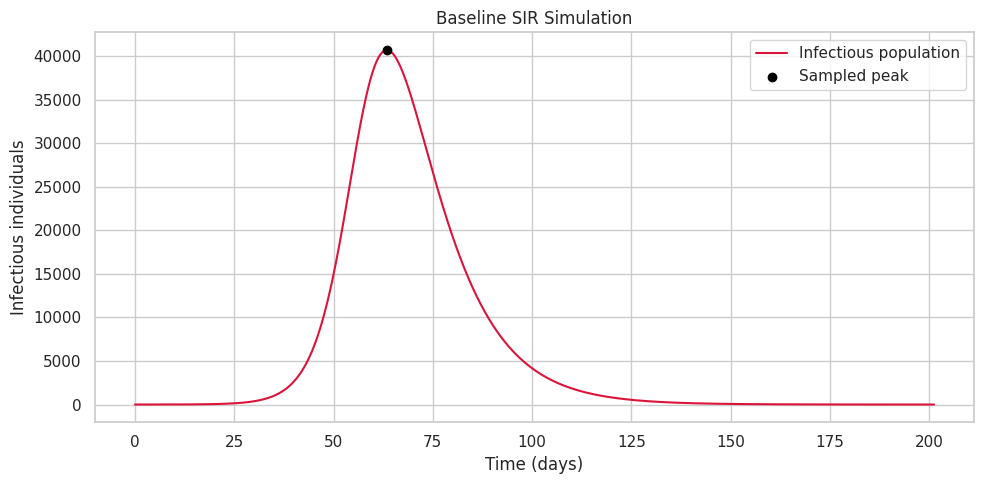

,t_peak,I_peak,end_time
0,63.4,40719.058,201.2


In [5]:
baseline_dt = 0.1

baseline = run_until_clearance(
    S0, I0, R0, beta, gamma, baseline_dt
)

baseline_metrics = extract_metrics(baseline)

plt.figure(figsize=(10, 5))

plt.plot(
    baseline["t"],
    baseline["I"],
    color="crimson",
    label="Infectious population"
)

plt.scatter(
    baseline_metrics["t_peak"],
    baseline_metrics["I_peak"],
    color="black",
    zorder=5,
    label="Sampled peak"
)

plt.xlabel("Time (days)")
plt.ylabel("Infectious individuals")
plt.title("Baseline SIR Simulation")
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame([baseline_metrics]).round(3))

,dt,t_peak,I_peak,peak_time_error_days,peak_size_error_pct,max_curve_error_pct
0,1.00,68.00,42167.5263,5.025,3.9063,29.3181
1,0.50,65.50,41352.4705,2.525,1.8979,14.9876
2,0.10,63.40,40719.0579,0.425,0.3371,2.7370
3,0.05,63.15,40640.7683,0.175,0.1442,1.1746


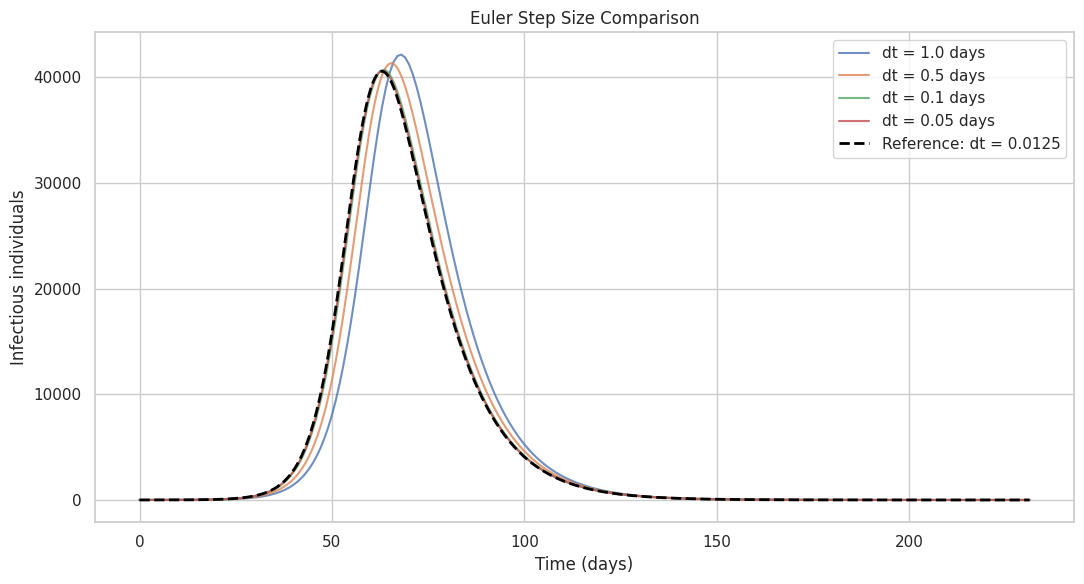

In [15]:
dt_values = [1.0, 0.5, 0.1, 0.05]
reference_dt = 0.0125

# Use a common horizon so all curves can be compared at the same times.
comparison_horizon = float(baseline["t"].iloc[-1] + 30)

reference = simulate_sir(
    S0, I0, R0, beta, gamma,
    reference_dt, comparison_horizon
)

reference_metrics = extract_metrics(reference)

comparison_runs = {}
comparison_rows = []

for step in dt_values:
    data = simulate_sir(
        S0, I0, R0, beta, gamma,
        step, comparison_horizon
    )

    comparison_runs[step] = data
    metrics = extract_metrics(data)

    # Interpolate the coarse solution onto the reference time grid.
    interpolated_I = np.interp(
        reference["t"],
        data["t"],
        data["I"]
    )

    curve_error_pct = (
        np.max(np.abs(interpolated_I - reference["I"].to_numpy()))
        / reference_metrics["I_peak"] * 100
    )

    comparison_rows.append({
        "dt": step,
        "t_peak": metrics["t_peak"],
        "I_peak": metrics["I_peak"],
        "peak_time_error_days": abs(
            metrics["t_peak"] - reference_metrics["t_peak"]
        ),
        "peak_size_error_pct": abs(
            metrics["I_peak"] - reference_metrics["I_peak"]
        ) / reference_metrics["I_peak"] * 100,
        "max_curve_error_pct": curve_error_pct,
    })

comparison_table = pd.DataFrame(comparison_rows)

display(comparison_table.round(4))

plt.figure(figsize=(11, 6))

for step, data in comparison_runs.items():
    plt.plot(
        data["t"], data["I"],
        label=f"dt = {step} days",
        alpha=0.8
    )

plt.plot(
    reference["t"], reference["I"],
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Reference: dt = {reference_dt}"
)

plt.xlabel("Time (days)")
plt.ylabel("Infectious individuals")
plt.title("Euler Step Size Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Start with the smallest previously tested step size.
candidate_dt = min(dt_values)

# Define numerical accuracy tolerances.
time_tolerance = 0.5
peak_tolerance_pct = 1.0
curve_tolerance_pct = 1.0

validation_rows = []
max_attempts = 12

for attempt in range(max_attempts):

    # Use a finer Euler solution as the numerical reference.
    fine_dt = candidate_dt / 8

    candidate = simulate_sir(
        S0, I0, R0, beta, gamma,
        candidate_dt, comparison_horizon
    )

    fine_reference = simulate_sir(
        S0, I0, R0, beta, gamma,
        fine_dt, comparison_horizon
    )

    candidate_metrics = extract_metrics(candidate)
    fine_metrics = extract_metrics(fine_reference)

    # Compare peak timing and peak magnitude.
    time_error = abs(
        candidate_metrics["t_peak"] - fine_metrics["t_peak"]
    )

    peak_error_pct = (
        abs(candidate_metrics["I_peak"] - fine_metrics["I_peak"])
        / fine_metrics["I_peak"] * 100
    )

    # Compare the full curves on the finer time grid.
    interpolated_I = np.interp(
        fine_reference["t"].to_numpy(),
        candidate["t"].to_numpy(),
        candidate["I"].to_numpy()
    )

    curve_error_pct = (
        np.max(
            np.abs(
                interpolated_I
                - fine_reference["I"].to_numpy()
            )
        )
        / fine_metrics["I_peak"] * 100
    )

    passed = (
        time_error <= time_tolerance
        and peak_error_pct <= peak_tolerance_pct
        and curve_error_pct <= curve_tolerance_pct
    )

    validation_rows.append({
        "dt": candidate_dt,
        "reference_dt": fine_dt,
        "peak_time_error_days": time_error,
        "peak_size_error_pct": peak_error_pct,
        "max_curve_error_pct": curve_error_pct,
        "passed": passed
    })

    if passed:
        validated_dt = candidate_dt
        break

    # Halve the step size and repeat the validation.
    candidate_dt /= 2

else:
    display(pd.DataFrame(validation_rows))
    raise RuntimeError(
        "Validation did not converge. Check the parameters "
        "and inspect the error table."
    )

validation_table = pd.DataFrame(validation_rows)

display(validation_table.round(6))

# Run the accepted baseline simulation until clearance.
baseline_validated = run_until_clearance(
    S0, I0, R0, beta, gamma, validated_dt
)

metrics = extract_metrics(baseline_validated)

# Check conservation of the total population.
population_error = np.max(
    np.abs(
        baseline_validated[["S", "I", "R"]].sum(axis=1) - N
    )
)

print(f"Validated dt: {validated_dt:.6f} days")
print(f"Peak timing: {metrics['t_peak']:.2f} days")
print(f"Peak magnitude: {metrics['I_peak']:,.0f} individuals")
print(f"Operational clearance: day {metrics['end_time']:.2f}")
print(f"Maximum population conservation error: {population_error:.8f}")

,dt,reference_dt,peak_time_error_days,peak_size_error_pct,max_curve_error_pct,passed
0,0.050,0.006250,0.20625,0.168217,1.370810,False
1,0.025,0.003125,0.11875,0.084028,0.685948,True


Validated dt: 0.025000 days
Peak timing: 63.05 days
Peak magnitude: 40,602 individuals
Operational clearance: day 201.38
Maximum population conservation error: 0.00000000


In [8]:
# Deliberately test very large time steps.
for large_dt in [5, 10, 20]:
    try:
        simulate_sir(
            S0, I0, R0, beta, gamma,
            large_dt, comparison_horizon
        )
        print(
            f"dt = {large_dt}: no negative values detected; "
            "accuracy still requires a convergence check."
        )

    except RuntimeError as error:
        print(f"dt = {large_dt}: {error}")

dt = 5: no negative values detected; accuracy still requires a convergence check.
dt = 10: Negative population encountered. Reduce dt.
dt = 20: Negative population encountered. Reduce dt.


In [9]:
reproduction_number = beta / gamma

initial_effective_reproduction_number = (
    reproduction_number * S0 / N
)

susceptible_threshold = N * gamma / beta

peak_index = baseline_validated["I"].idxmax()
susceptible_at_peak = baseline_validated.loc[peak_index, "S"]

print(f"Basic reproduction number: {reproduction_number:.3f}")
print(
    "Initial effective reproduction number: "
    f"{initial_effective_reproduction_number:.3f}"
)
print(
    "Theoretical susceptible population at the peak: "
    f"{susceptible_threshold:,.0f}"
)
print(
    "Simulated susceptible population at the sampled peak: "
    f"{susceptible_at_peak:,.0f}"
)

Basic reproduction number: 3.000
Initial effective reproduction number: 3.000
Theoretical susceptible population at the peak: 45,000
Simulated susceptible population at the sampled peak: 44,905


In [10]:
# Explore illustrative ranges around the baseline parameters.
beta_values = np.linspace(beta * 0.5, beta * 1.5, 15)
gamma_values = np.linspace(gamma * 0.5, gamma * 1.5, 15)

sensitivity_rows = []

for gamma_value in gamma_values:
    for beta_value in beta_values:
        data = run_until_clearance(
            S0, I0, R0,
            beta_value, gamma_value,
            validated_dt
        )

        result = extract_metrics(data)

        sensitivity_rows.append({
            "beta": beta_value,
            "gamma": gamma_value,
            "reproduction_number": beta_value / gamma_value,
            "t_peak": result["t_peak"],
            "I_peak": result["I_peak"],
        })

sensitivity = pd.DataFrame(sensitivity_rows)

display(sensitivity.head())
print(f"Completed {len(sensitivity)} parameter combinations.")

,beta,gamma,reproduction_number,t_peak,I_peak
0,0.150000,0.05,3.000000,125.950,40582.260912
1,0.171429,0.05,3.428571,105.650,47135.161167
2,0.192857,0.05,3.857143,91.125,52784.298662
3,0.214286,0.05,4.285714,80.225,57695.960282
4,0.235714,0.05,4.714286,71.700,62003.247653


Completed 225 parameter combinations.


In [11]:
grid_checks = []

for row in sensitivity.itertuples(index=False):
    finer_data = run_until_clearance(
        S0, I0, R0,
        row.beta, row.gamma,
        validated_dt / 2
    )

    finer_metrics = extract_metrics(finer_data)

    grid_checks.append({
        "time_change_days": abs(
            row.t_peak - finer_metrics["t_peak"]
        ),
        "peak_change_pct": abs(
            row.I_peak - finer_metrics["I_peak"]
        ) / finer_metrics["I_peak"] * 100,
    })

grid_validation = pd.DataFrame(grid_checks)

display(grid_validation.max().to_frame("Maximum change"))

if (
    grid_validation["time_change_days"].max() > 0.5
    or grid_validation["peak_change_pct"].max() > 1.0
):
    raise RuntimeError(
        "Grid validation failed. Reduce validated_dt and rerun Cells 10–11."
    )

print("The parameter grid passed the step-halving checks.")

,Maximum change
time_change_days,0.075000
peak_change_pct,0.072066


The parameter grid passed the step-halving checks.


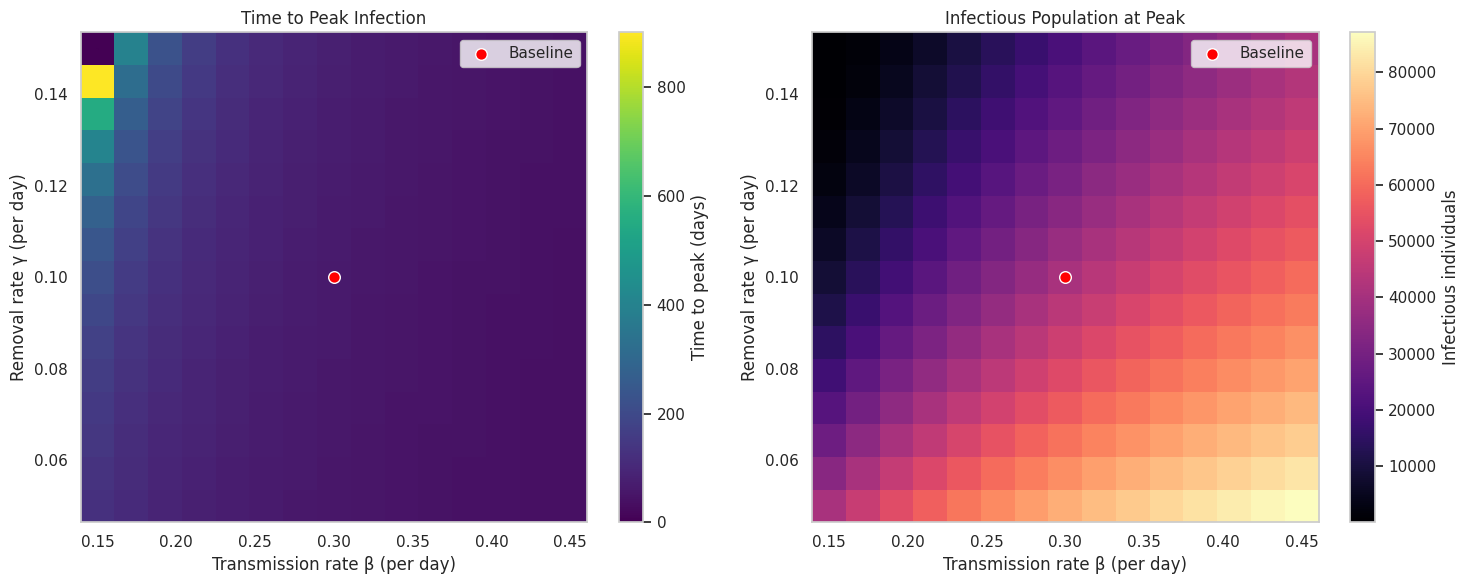

In [12]:
time_surface = sensitivity.pivot(
    index="gamma",
    columns="beta",
    values="t_peak"
)

size_surface = sensitivity.pivot(
    index="gamma",
    columns="beta",
    values="I_peak"
)

B, G = np.meshgrid(beta_values, gamma_values)
initial_reff_surface = (B / G) * (S0 / N)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

surfaces = [
    (
        time_surface,
        "Time to Peak Infection",
        "Time to peak (days)",
        "viridis"
    ),
    (
        size_surface,
        "Infectious Population at Peak",
        "Infectious individuals",
        "magma"
    ),
]

for ax, (surface, title, colorbar_label, cmap) in zip(axes, surfaces):
    plot = ax.pcolormesh(
        B, G, surface.to_numpy(),
        shading="auto",
        cmap=cmap
    )

    fig.colorbar(plot, ax=ax, label=colorbar_label)

    if initial_reff_surface.min() < 1 < initial_reff_surface.max():
        ax.contour(
            B, G, initial_reff_surface,
            levels=[1],
            colors="black",
            linestyles="--",
            linewidths=1.5
        )

    ax.scatter(
        beta, gamma,
        color="red",
        edgecolors="white",
        s=70,
        label="Baseline"
    )

    ax.set_xlabel("Transmission rate β (per day)")
    ax.set_ylabel("Removal rate γ (per day)")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

In [13]:
timing = time_surface.to_numpy()
beta_intervals = np.diff(beta_values)

# Estimate timing sensitivity between adjacent beta values.
timing_slope = np.diff(timing, axis=1) / beta_intervals

# Restrict comparisons to pairs with epidemic growth at both endpoints.
growing_pairs = (
    (initial_reff_surface[:, :-1] > 1)
    & (initial_reff_surface[:, 1:] > 1)
)

sensitivity_comparisons = []

for row_index, column_index in np.argwhere(growing_pairs):
    sensitivity_comparisons.append({
        "gamma": gamma_values[row_index],
        "beta_low": beta_values[column_index],
        "beta_high": beta_values[column_index + 1],
        "absolute_timing_slope": abs(
            timing_slope[row_index, column_index]
        ),
    })

timing_sensitivity = pd.DataFrame(sensitivity_comparisons)

if not timing_sensitivity.empty:
    print("Most sensitive adjacent beta intervals:")
    display(
        timing_sensitivity.nlargest(
            5, "absolute_timing_slope"
        ).round(4)
    )

    print("Least sensitive adjacent beta intervals:")
    display(
        timing_sensitivity.nsmallest(
            5, "absolute_timing_slope"
        ).round(4)
    )

Most sensitive adjacent beta intervals:


,gamma,beta_low,beta_high,absolute_timing_slope
182,0.1429,0.1500,0.1714,27258.0000
168,0.1357,0.1500,0.1714,13249.8333
154,0.1286,0.1500,0.1714,8174.8333
196,0.1500,0.1714,0.1929,7843.5000
140,0.1214,0.1500,0.1714,5652.5000


Least sensitive adjacent beta intervals:


,gamma,beta_low,beta_high,absolute_timing_slope
13,0.0500,0.4286,0.45,86.3333
27,0.0571,0.4286,0.45,87.5000
41,0.0643,0.4286,0.45,89.8333
55,0.0714,0.4286,0.45,93.3333
69,0.0786,0.4286,0.45,95.6667


,beta_reduction_pct,adjusted_beta,initial_Reff,t_peak,I_peak,peak_delay_days,epidemic_growth
0,0.0,0.30,3.0,63.050,40601.737,0.000,True
1,20.0,0.24,2.4,86.775,29527.657,23.725,True
2,40.0,0.18,1.8,142.050,15924.552,79.000,True
3,60.0,0.12,1.2,453.400,1989.963,390.350,True
4,70.0,0.09,0.9,0.000,1.000,NaN,False


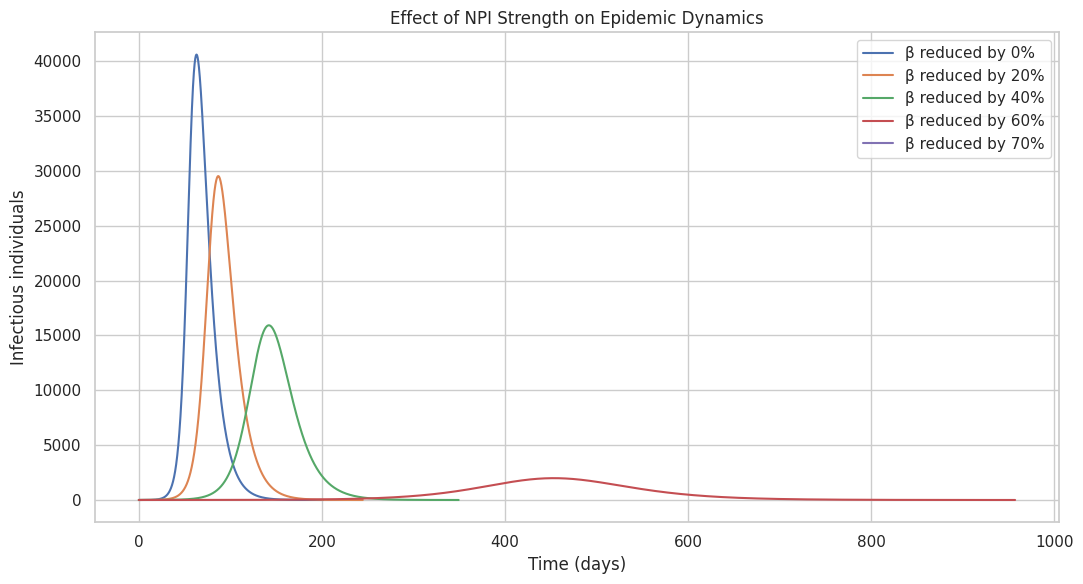

Minimum beta reduction for initial Reff <= 1: 66.67%


In [14]:
npi_reductions = [0.0, 0.2, 0.4, 0.6, 0.7]

npi_rows = []
npi_runs = {}

for reduction in npi_reductions:
    adjusted_beta = beta * (1 - reduction)

    data = run_until_clearance(
        S0, I0, R0,
        adjusted_beta, gamma,
        validated_dt
    )

    result = extract_metrics(data)
    initial_reff = adjusted_beta / gamma * S0 / N

    npi_runs[reduction] = data

    npi_rows.append({
        "beta_reduction_pct": reduction * 100,
        "adjusted_beta": adjusted_beta,
        "initial_Reff": initial_reff,
        "t_peak": result["t_peak"],
        "I_peak": result["I_peak"],
        "peak_delay_days": (
            result["t_peak"] - metrics["t_peak"]
            if initial_reff > 1 else np.nan
        ),
        "epidemic_growth": initial_reff > 1,
    })

npi_results = pd.DataFrame(npi_rows)

display(npi_results.round(3))

plt.figure(figsize=(11, 6))

for reduction, data in npi_runs.items():
    plt.plot(
        data["t"],
        data["I"],
        label=f"β reduced by {reduction:.0%}"
    )

plt.xlabel("Time (days)")
plt.ylabel("Infectious individuals")
plt.title("Effect of NPI Strength on Epidemic Dynamics")
plt.legend()
plt.tight_layout()
plt.show()

# Calculate the reduction needed to prevent initial epidemic growth.
critical_reduction = max(
    0.0,
    1 - gamma / (beta * S0 / N)
)

print(
    "Minimum beta reduction for initial Reff <= 1: "
    f"{critical_reduction:.2%}"
)